In [1]:
# Web based Jupyter Notebook.
import micropip; 
await micropip.install('pandas')
#await micropip.install('pandas==0.24.2', reinstall=True, keep_going=True)
await micropip.install('pandas_ml')
await micropip.install('matplotlib')
await micropip.install('scikit-learn')
await micropip.install('scikit-plot')


In [2]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report


import pandas as pd, numpy as np

import matplotlib.pyplot as plt 
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches


In [3]:
import pandas as pd
df_churn_pd=pd.read_csv('mergedcustomers.csv')      #The variable in the code shared by the excerise project.
df_churn_pd.head()


,ID,CHURNRISK,GENDER,STATUS,CHILDREN,ESTINCOME,HOMEOWNER,AGE,TOTALDOLLARVALUETRADED,TOTALUNITSTRADED,LARGESTSINGLETRANSACTION,SMALLESTSINGLETRANSACTION,PERCENTCHANGECALCULATION,DAYSSINCELASTLOGIN,DAYSSINCELASTTRADE,NETREALIZEDGAINS_YTD,NETREALIZEDLOSSES_YTD
0,1703,Medium,M,M,2,28766.9,N,47,6110.61,58,1527.6525,152.76525,8.70,2,13,0.0000,152.76525
1,1704,Low,M,M,2,91272.2,Y,25,26992.70,13,13496.3500,1349.63500,3.25,4,10,1349.6350,0.00000
2,1705,Low,F,S,0,73228.3,N,42,22472.25,28,11236.1250,1123.61250,7.00,4,5,1123.6125,0.00000
3,1706,High,M,M,1,64792.3,N,52,13051.31,36,6525.6550,652.56550,9.00,3,6,0.0000,652.56550
4,1707,High,F,S,0,93322.1,Y,40,29922.99,8,14961.4950,1496.14950,2.00,4,9,0.0000,1496.14950


In [4]:
print('The dataset containing columns of the following data types: \n ' + str(df_churn_pd.dtypes))

The dataset containing columns of the following data types: 
 ID                             int64
CHURNRISK                        str
GENDER                           str
STATUS                           str
CHILDREN                       int64
ESTINCOME                    float64
HOMEOWNER                        str
AGE                            int64
TOTALDOLLARVALUETRADED       float64
TOTALUNITSTRADED               int64
LARGESTSINGLETRANSACTION     float64
SMALLESTSINGLETRANSACTION    float64
PERCENTCHANGECALCULATION     float64
DAYSSINCELASTLOGIN             int64
DAYSSINCELASTTRADE             int64
NETREALIZEDGAINS_YTD         float64
NETREALIZEDLOSSES_YTD        float64
dtype: object


Each category in the CHURNRISK column has the following count:

CHURNRISK
High      983
Low       699
Medium    384
dtype: int64


Text(0, 0.5, 'Frequency')

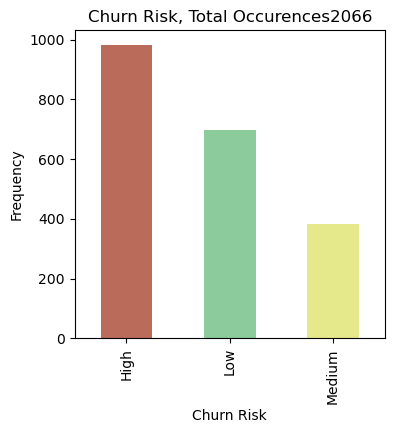

In [5]:
print("Each category in the CHURNRISK column has the following count:\n")
print(df_churn_pd.groupby(['CHURNRISK']).size())

#Bar chart to show the split of data.

index=['High','Medium','Low']
churn_plot = df_churn_pd['CHURNRISK'].value_counts(sort=True, ascending=False).plot(kind='bar', figsize=(4,4), 
title="Churn Risk, Total Occurences" + str(df_churn_pd['CHURNRISK'].count()), color=['#BB6B5A','#8CCB9B','#E5E88B'])
churn_plot.set_xlabel("Churn Risk")
churn_plot.set_ylabel("Frequency")

In [6]:
#Drop the data columns, that aren't required.
df_churn_pd = df_churn_pd.drop(['ID'],axis=1)
df_churn_pd.head()


,CHURNRISK,GENDER,STATUS,CHILDREN,ESTINCOME,HOMEOWNER,AGE,TOTALDOLLARVALUETRADED,TOTALUNITSTRADED,LARGESTSINGLETRANSACTION,SMALLESTSINGLETRANSACTION,PERCENTCHANGECALCULATION,DAYSSINCELASTLOGIN,DAYSSINCELASTTRADE,NETREALIZEDGAINS_YTD,NETREALIZEDLOSSES_YTD
0,Medium,M,M,2,28766.9,N,47,6110.61,58,1527.6525,152.76525,8.70,2,13,0.0000,152.76525
1,Low,M,M,2,91272.2,Y,25,26992.70,13,13496.3500,1349.63500,3.25,4,10,1349.6350,0.00000
2,Low,F,S,0,73228.3,N,42,22472.25,28,11236.1250,1123.61250,7.00,4,5,1123.6125,0.00000
3,High,M,M,1,64792.3,N,52,13051.31,36,6525.6550,652.56550,9.00,3,6,0.0000,652.56550
4,High,F,S,0,93322.1,Y,40,29922.99,8,14961.4950,1496.14950,2.00,4,9,0.0000,1496.14950


In [7]:
#Define the categorical columns.

categoricalColumns = ['GENDER','STATUS','HOMEOWNER']
print('<<Categorical Columns>>')
print(categoricalColumns)

impute_categorical = SimpleImputer(strategy="most_frequent")

one_hot_categorical = OneHotEncoder(handle_unknown='ignore')

categorical_transformer = Pipeline(steps=[('impute', impute_categorical), ('onehot', one_hot_categorical)])



<<Categorical Columns>>
['GENDER', 'STATUS', 'HOMEOWNER']


In [8]:
#Define the numerical columns.
numericalColumns = df_churn_pd.select_dtypes(include=[float,int]).columns

print("<<Numerical Columns>>")
print(numericalColumns)

scaler_numerical = StandardScaler()

numerical_transformer = Pipeline(steps=[('scale', scaler_numerical)])

<<Numerical Columns>>
Index(['CHILDREN', 'ESTINCOME', 'AGE', 'TOTALDOLLARVALUETRADED',
       'TOTALUNITSTRADED', 'LARGESTSINGLETRANSACTION',
       'SMALLESTSINGLETRANSACTION', 'PERCENTCHANGECALCULATION',
       'DAYSSINCELASTLOGIN', 'DAYSSINCELASTTRADE', 'NETREALIZEDGAINS_YTD',
       'NETREALIZEDLOSSES_YTD'],
      dtype='str')


In [9]:
preprocessorForCategoricalColumns = ColumnTransformer(transformers=[('cat', categorical_transformer, categoricalColumns)], 
                                                      remainder="passthrough")

preprocessorForAllColumns = ColumnTransformer(transformers=[('cat', categorical_transformer, categoricalColumns), 
                                              ('num', numerical_transformer, numericalColumns)], remainder="passthrough")

#The transformation happens in the pipeline, showing here temporarily.

df_churn_pd_temp = preprocessorForCategoricalColumns.fit_transform(df_churn_pd)
print("<<Data After Transforming Categorical Columns>>")
print(df_churn_pd_temp)

df_churn_pd_temp2 = preprocessorForAllColumns.fit_transform(df_churn_pd)
print("\n\n<<Data After Transforming All Columns>>")
print(df_churn_pd_temp2)





<<Data After Transforming Categorical Columns>>
[[0.0 1.0 0.0 ... 13 0.0 152.76525]
 [0.0 1.0 0.0 ... 10 1349.635 0.0]
 [1.0 0.0 0.0 ... 5 1123.6125 0.0]
 ...
 [1.0 0.0 0.0 ... 11 0.0 82.50825]
 [1.0 0.0 0.0 ... 5 930.093 0.0]
 [0.0 1.0 0.0 ... 8 1041.604 0.0]]


<<Data After Transforming All Columns>>
[[0.0 1.0 0.0 ... -0.6792731303453047 -0.5106065181930338 'Medium']
 [0.0 1.0 0.0 ... 1.8354629319820521 -0.7959345330293706 'Low']
 [1.0 0.0 0.0 ... 1.4143217110983428 -0.7959345330293706 'Low']
 ...
 [1.0 0.0 0.0 ... -0.6792731303453047 -0.6418293606808149 'Medium']
 [1.0 0.0 0.0 ... 1.053742394902809 -0.7959345330293706 'Low']
 [0.0 1.0 0.0 ... 1.261517632686496 -0.7959345330293706 'Low']]


In [10]:
#Prepare data frame into train and test sets.

features = []
features = df_churn_pd.drop(['CHURNRISK'], axis=1)

label_churn = pd.DataFrame(df_churn_pd, columns=['CHURNRISK'])
label_encoder = LabelEncoder()
label = df_churn_pd['CHURNRISK']

label = label_encoder.fit_transform(label)
print('Encoded value for ChurnRisk after applying the label encoder' + str(label) )


Encoded value for ChurnRisk after applying the label encoder[2 1 1 ... 2 1 1]


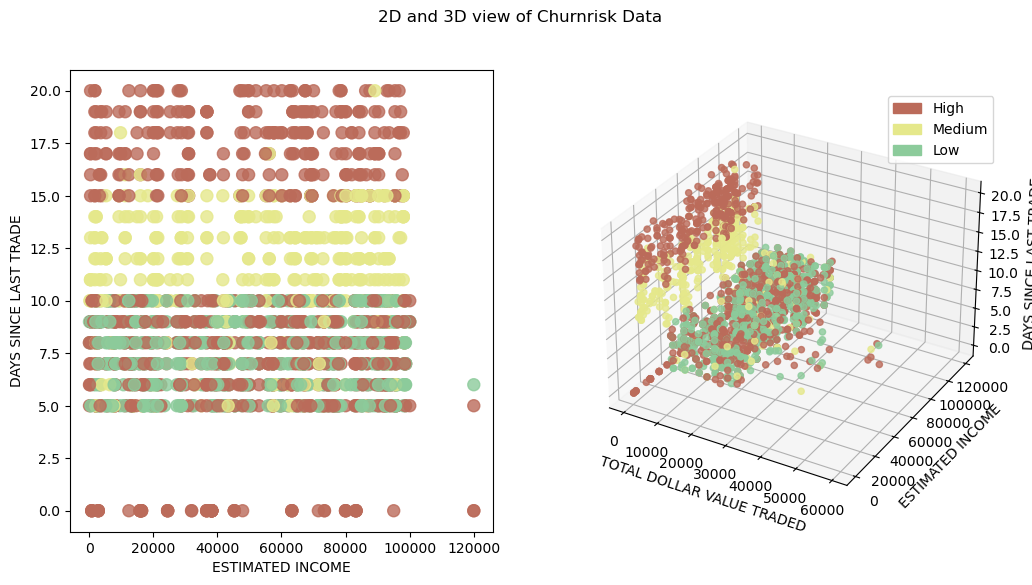

In [11]:
area=75

x = df_churn_pd['ESTINCOME']
y = df_churn_pd['DAYSSINCELASTTRADE']
z = df_churn_pd['TOTALDOLLARVALUETRADED']

pop_a = mpatches.Patch(color='#BB6B5A', label='High')
pop_b = mpatches.Patch(color='#E5E88B', label='Medium')
pop_c = mpatches.Patch(color='#8CCB9B', label='Low')

#Helper Methods for Graph Generation.
def colormap(risk_list):
    cols=[]
    for l in risk_list:
        if l==0:
            cols.append('#BB6B5A')
        elif l==1:
            cols.append('#8CCB9B')
        elif l==2:
            cols.append('#E5E88B')
    return cols

fig = plt.figure(figsize=[12,6])
fig.suptitle('2D and 3D view of Churnrisk Data')

#First subplot
ax = fig.add_subplot(1, 2, 1)
ax.scatter(x, y, alpha=0.8, c=colormap(label), s=area)
ax.set_xlabel('ESTIMATED INCOME')
ax.set_ylabel('DAYS SINCE LAST TRADE')

#Second subplot
ax = fig.add_subplot(1,2,2, projection='3d')
ax.scatter(z, x, y, alpha=0.8, c=colormap(label), marker='o')
ax.set_xlabel('TOTAL DOLLAR VALUE TRADED')
ax.set_ylabel('ESTIMATED INCOME')
ax.set_zlabel('DAYS SINCE LAST TRADE')

plt.legend(handles=[pop_a, pop_b, pop_c])

plt.show()


In [12]:
def two_d_compare(y_test, y_pred, model_name):
    area = (12 * np.random.rand(40))**2
    plt.subplots(ncols=2, figsize=(10,4))
    plt.suptitle('Actual vs Predicted Data: '+ model_name + '. Accuracy : %.2f' % accuracy_score(y_test, y_pred))

    # 1. Define your legend handles (adjust the colors and labels to match your data)
    pop_a = mpatches.Patch(color="red", label="Class A")
    pop_b = mpatches.Patch(color="green", label="Class B")
    pop_c = mpatches.Patch(color="blue", label="Class C")
    
    plt.subplot(121)
    plt.scatter(X_Test['ESTINCOME'], X_Test['DAYSSINCELASTTRADE'], alpha=0.8, c=colormap(y_test))
    plt.title('Actual')
    plt.legend(handles=[pop_a, pop_b, pop_c])
    plt.title('Predicted')

    # 2. Plotting the Predicted Data (Fixed & Completed)
    plt.subplot(122)
    plt.scatter(X_Test['ESTINCOME'], X_Test['DAYSSINCELASTTRADE'], alpha=0.8, c=colormap(y_pred))
    plt.title('Predicted')
    plt.legend(handles=[pop_a, pop_b, pop_c])
    
    plt.show()

    
def model_matrix(y_test, y_pred):
    print("Decoded values of Churnrisk after applying inverse of label encoder : " + str(np.unique(y_pred)))

    skplt.matrix.plot.confusion_matrix(y_test, y_pred, text_fontsize="small", cmap='Greens', figsize=(6,4))
    plt.show()

    print("The Classification Report for the model: \n\n"+ classification_report(y_test,y_pred))

    

In [13]:
#Training the model.

X_Train, X_Test, Y_Train, Y_Test = train_test_split(features, label, random_state=0)

print("Dimensions for the dataset which will be used for training: Input Features"+str(X_Train.shape)+
      "Output Label"+str(Y_Train.shape))
print("Dimensions for the dataset which will be used for testing: Input Features"+str(X_Test.shape)+
      "Output Label"+str(Y_Test.shape))

#Training the model.

from sklearn.ensemble import RandomForestClassifier

model_name = "Random Forest Classifier"

randomForestClassifer = RandomForestClassifier(n_estimators=100, max_depth=2, random_state=0)

Dimensions for the dataset which will be used for training: Input Features(1549, 15)Output Label(1549,)
Dimensions for the dataset which will be used for testing: Input Features(517, 15)Output Label(517,)


In [47]:
rfc_model = Pipeline(steps=[('preprocessAll',preprocessorForAllColumns), ('classifier', randomForestClassifer)])

In [48]:
#Build Models.
rfc_model.fit(X_Train, Y_Train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessAll', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different tr

In [49]:
#Test the Random Forest Classifier Model.
y_pred_rfc = rfc_model.predict(X_Test)

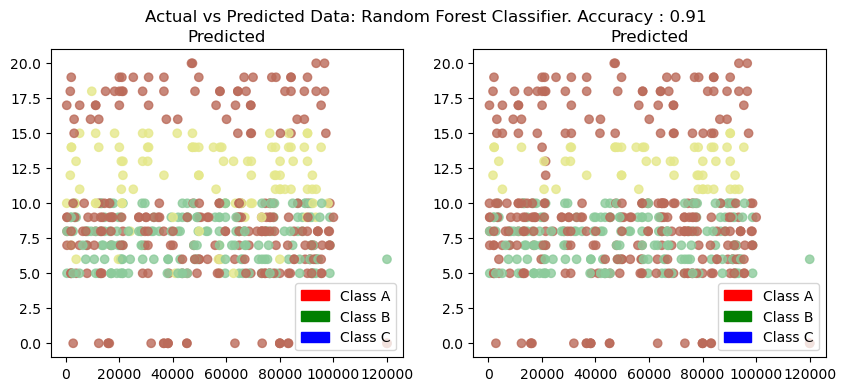

In [50]:
two_d_compare(Y_Test, y_pred_rfc, model_name)